# 🤖 MesaTI — Agente de Soporte TI con LangGraph
**ISY0101 · Ingeniería de Soluciones con IA · Evaluación Parcial N°2**

Este notebook evoluciona el pipeline RAG de la EP1 hacia un **agente funcional** que:

| Requisito de la pauta | Dónde se implementa |
|---|---|
| **IE1** Herramientas de consulta, escritura y razonamiento | Sección 5 (8 herramientas) |
| **IE2** Framework de agentes | LangChain + **LangGraph** (`StateGraph`), Sección 7 |
| **IE3** Memoria de contenido (corto y largo plazo) | Checkpointer SQLite + resumen + memoria Chroma, Secciones 6–7 |
| **IE4** Recuperación de contexto semántico | RAG con relevancia + memoria episódica filtrada por usuario |
| **IE5** Planificación y priorización | Nodo `planificador` con salida estructurada + replanificación |
| **IE7** Decisiones adaptativas | Escenarios de la Sección 9 (servicio caído, fuera de KB, multi-problema) |
| Evidencia de pruebas | Pruebas unitarias de herramientas, Sección 8 |

## 1. Instalación de dependencias

In [ ]:
!pip install -q -U langchain langchain-core langchain-community langchain-groq langchain-huggingface langchain-chroma langchain-text-splitters langgraph langgraph-checkpoint-sqlite chromadb sentence-transformers pypdf python-dotenv gradio

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.1 which is incompatible.


## 2. Configuración del entorno

> ⚠️ **Seguridad:** la API key **nunca** se escribe en el código (el repositorio será público).
> Se lee desde una variable de entorno, un archivo `.env` (excluido en `.gitignore`), los *Secrets* de Colab, o se pide por teclado.

In [ ]:
import os, json, getpass, re
from datetime import datetime, timedelta
from dotenv import load_dotenv

load_dotenv()
if not os.environ.get("GROQ_API_KEY"):
    try:
        from google.colab import userdata
        os.environ["GROQ_API_KEY"] = userdata.get("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")
    except Exception:
        os.environ["GROQ_API_KEY"] = getpass.getpass("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")


MODELO_LLM = os.environ.get("MODELO_LLM", "qwen/qwen3.8-27b")

DATA_DIR    = "data"
CHROMA_DIR  = "chroma_db"
MEMORIA_DIR = "memoria"
for d in (DATA_DIR, CHROMA_DIR, MEMORIA_DIR):
    os.makedirs(d, exist_ok=True)

TICKETS_PATH          = os.path.join(MEMORIA_DIR, "tickets.json")
ESTADO_SERVICIOS_PATH = os.path.join(MEMORIA_DIR, "estado_servicios.json")
PERFILES_PATH         = os.path.join(MEMORIA_DIR, "perfiles_usuarios.json")
CHECKPOINT_DB         = os.path.join(MEMORIA_DIR, "checkpoints.sqlite")

# Parámetros de comportamiento del agente
UMBRAL_RELEVANCIA = 0.35   # bajo este puntaje un fragmento se considera no relevante
MAX_TURNOS_CP     = 6      # turnos completos que se mantienen literales en memoria de corto plazo
MAX_REPLAN        = 2      # replanificaciones máximas por turno (evita ciclos)

print(f"✅ Entorno listo | modelo: {MODELO_LLM}")

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··········
✅ Entorno listo | modelo: qwen/qwen3.8-27b


## 3. Base de conocimientos y entorno organizacional simulado

Además del documento de conocimiento (EP1), se simula el **entorno** con el que interactúa el agente:
- `estado_servicios.json`: estado de cada servicio TI (puede cambiar durante la ejecución → *condiciones cambiantes*).
- `tickets.json`: sistema de tickets donde el agente **escribe**.
- `perfiles_usuarios.json`: datos estables de cada usuario (memoria de largo plazo estructurada).

In [ ]:
doc_path = os.path.join(DATA_DIR, "documento_conocimiento.txt")

contenido_base = '''
Base de Conocimientos Oficial - Soporte TI Duoc UC
--------------------------------------------------
1. Bloqueo de cuentas: Si un usuario olvida su contraseña o la cuenta se bloquea tras 3 intentos fallidos, debe contactar al administrador de red local o utilizar el portal de autoservicio para restablecerla mediante correo institucional.

2. Configuración de VPN: Para acceder remotamente a los laboratorios, es obligatorio utilizar la VPN corporativa con autenticación de doble factor (2FA).

3. Impresoras de red: Si una impresora muestra el estado 'En pausa', reinicie el servicio de cola de impresión en Windows (services.msc -> Cola de impresión -> Reiniciar).

4. Actualizaciones de software: Las actualizaciones críticas del sistema operativo se despliegan automáticamente todos los viernes a las 22:00 hrs.

5. Correo institucional: Si el correo no sincroniza en el celular, elimine la cuenta del dispositivo y vuelva a agregarla usando autenticación moderna con 2FA.

6. Red Wi-Fi: La red inalámbrica institucional requiere ingresar con las credenciales del correo institucional. Si no conecta, olvide la red y vuelva a conectarse.

7. Política de escalamiento: Todo incidente que no pueda resolverse con esta base de conocimientos, o que afecte a un servicio caído, debe registrarse como ticket para el equipo de Soporte Nivel 2.

8. Niveles de servicio (SLA): P1 crítico = 4 horas, P2 alto = 8 horas, P3 medio = 24 horas, P4 bajo = 72 horas.
'''

with open(doc_path, "w", encoding="utf-8") as f:
    f.write(contenido_base)

def _leer_json(path, default):
    if not os.path.exists(path):
        return default
    with open(path, encoding="utf-8") as f:
        return json.load(f)

def _escribir_json(path, data):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False, indent=2)

ESTADO_INICIAL = {"vpn": "operativo", "correo": "operativo", "impresion": "operativo",
                  "portal_autoservicio": "operativo", "wifi": "operativo"}
if not os.path.exists(ESTADO_SERVICIOS_PATH): _escribir_json(ESTADO_SERVICIOS_PATH, ESTADO_INICIAL)
if not os.path.exists(TICKETS_PATH):          _escribir_json(TICKETS_PATH, [])
if not os.path.exists(PERFILES_PATH):         _escribir_json(PERFILES_PATH, {})

def simular_cambio_servicio(servicio: str, estado: str):
    '''Simula un cambio en el entorno (operativo / degradado / caido). Útil para la demo en vivo.'''
    estados = _leer_json(ESTADO_SERVICIOS_PATH, ESTADO_INICIAL)
    estados[servicio] = estado
    _escribir_json(ESTADO_SERVICIOS_PATH, estados)
    print(f"🌐 Entorno: el servicio '{servicio}' ahora está '{estado}'")

print("✅ Base de conocimientos y entorno simulado listos")

✅ Base de conocimientos y entorno simulado listos


## 4. Recuperación semántica: base de conocimientos y memoria de largo plazo (IE4)

Mejoras respecto a la EP1:
- Embeddings **multilingües** (`paraphrase-multilingual-MiniLM-L12-v2`), más adecuados para consultas en español.
- Distancia **coseno** y **puntaje de relevancia**: el agente sabe cuándo *no* encontró información útil y decide escalar.
- IDs determinísticos: re-ejecutar la celda no duplica fragmentos en Chroma.
- Una segunda colección, `memoria_largo_plazo`, guarda resúmenes de interacciones por usuario para recuperarlos semánticamente en sesiones futuras.

In [ ]:
import hashlib
from langchain_community.document_loaders import TextLoader, DirectoryLoader, PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
    encode_kwargs={"normalize_embeddings": True},
)

def cargar_documentos():
    loaders = [
        DirectoryLoader(DATA_DIR, glob="**/*.txt", loader_cls=TextLoader, loader_kwargs={"encoding": "utf-8"}),
        DirectoryLoader(DATA_DIR, glob="**/*.pdf", loader_cls=PyPDFLoader),
    ]
    docs = []
    for loader in loaders:
        try:
            docs.extend(loader.load())
        except Exception as e:
            print(f"Aviso cargando documentos: {e}")
    return docs

splitter = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=60, separators=["\n\n", "\n", ". ", " "])
chunks = splitter.split_documents(cargar_documentos())

kb = Chroma(collection_name="base_conocimiento", embedding_function=embeddings,
            persist_directory=CHROMA_DIR, collection_metadata={"hnsw:space": "cosine"})
ids = [hashlib.md5(c.page_content.encode("utf-8")).hexdigest() for c in chunks]
kb.add_documents(chunks, ids=ids)

memoria_lp = Chroma(collection_name="memoria_largo_plazo", embedding_function=embeddings,
                    persist_directory=CHROMA_DIR, collection_metadata={"hnsw:space": "cosine"})

print(f"✅ {len(chunks)} fragmentos indexados en la base de conocimientos")

# Verificación rápida de la recuperación con puntajes
for q in ["se me bloqueó la cuenta", "¿cómo instalo AutoCAD?"]:
    res = kb.similarity_search_with_relevance_scores(q, k=1)
    print(f"  '{q}' → relevancia {res[0][1]:.2f}: {res[0][0].page_content[:60]}...")

/tmp/ipykernel_794/2274012815.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import TextLoader, DirectoryLoader, PyPDFLoader


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

✅ 5 fragmentos indexados en la base de conocimientos
  'se me bloqueó la cuenta' → relevancia 0.41: Base de Conocimientos Oficial - Soporte TI Duoc UC
---------...
  '¿cómo instalo AutoCAD?' → relevancia 0.10: 4. Actualizaciones de software: Las actualizaciones críticas...


## 5. Herramientas del agente

| Tipo | Herramienta | Función |
|---|---|---|
| 🔎 Consulta | `buscar_base_conocimiento` | RAG con umbral de relevancia |
| 🔎 Consulta | `consultar_estado_servicio` | Lee el estado del entorno; emite `[REPLANIFICAR]` si hay incidencia |
| 🔎 Consulta | `consultar_tickets` | Lista/consulta tickets del usuario |
| 🔎 Consulta | `recordar_historial_usuario` | Búsqueda semántica en memoria de largo plazo |
| ✍️ Escritura | `crear_ticket` | Registra ticket (evita duplicados abiertos de la misma categoría) |
| ✍️ Escritura | `actualizar_ticket` | Cambia estado y agrega notas |
| ✍️ Escritura | `guardar_dato_usuario` | Persiste datos estables del usuario |
| 🧮 Razonamiento | `clasificar_prioridad` | Matriz impacto × urgencia → prioridad P1–P4 y SLA |

El `user_id` se inyecta desde la configuración de LangGraph (`RunnableConfig`), por lo que el LLM no puede suplantar a otro usuario.

In [ ]:
from langchain_core.tools import tool
from langchain_core.runnables import RunnableConfig

def _usuario(config) -> str:
    return (config or {}).get("configurable", {}).get("user_id", "anonimo")

# ---------- Herramientas de CONSULTA ----------
@tool
def buscar_base_conocimiento(consulta: str) -> str:
    '''Busca procedimientos oficiales en la base de conocimientos de Soporte TI.
    Úsala SIEMPRE antes de entregar instrucciones técnicas al usuario.'''
    resultados = kb.similarity_search_with_relevance_scores(consulta, k=3)
    relevantes = [(d, s) for d, s in resultados if s >= UMBRAL_RELEVANCIA]
    if not relevantes:
        return ("[SIN_RESULTADOS] No hay información relevante en la base de conocimientos para esta consulta. "
                "Según la política de escalamiento, corresponde registrar un ticket si el usuario reporta un problema.")
    return "\n\n".join(f"[Fuente {i} | relevancia {s:.2f}] {d.page_content.strip()}"
                       for i, (d, s) in enumerate(relevantes, 1))

@tool
def consultar_estado_servicio(servicio: str) -> str:
    '''Consulta el estado actual de un servicio TI. Servicios válidos: vpn, correo, impresion, portal_autoservicio, wifi.'''
    estados = _leer_json(ESTADO_SERVICIOS_PATH, ESTADO_INICIAL)
    clave = servicio.strip().lower().replace(" ", "_").replace("ó", "o")
    if clave not in estados:
        return f"Servicio '{servicio}' no reconocido. Servicios disponibles: {', '.join(estados)}."
    estado = estados[clave]
    if estado != "operativo":
        return (f"[REPLANIFICAR] ALERTA: el servicio '{clave}' está {estado.upper()}. "
                "Los procedimientos habituales no resolverán el problema: informa la incidencia al usuario "
                "y registra (o vincula) un ticket.")
    return f"El servicio '{clave}' está operativo."

@tool
def consultar_tickets(config: RunnableConfig, ticket_id: str = "") -> str:
    '''Consulta los tickets del usuario actual. Si se entrega ticket_id, muestra solo ese ticket.'''
    uid = _usuario(config)
    tickets = [t for t in _leer_json(TICKETS_PATH, []) if t["usuario"] == uid]
    if ticket_id:
        tickets = [t for t in tickets if t["id"] == ticket_id.strip().upper()]
    if not tickets:
        return "No se encontraron tickets para este usuario."
    return "\n".join(f"{t['id']} | {t['estado']} | {t['prioridad']} | {t['categoria']} | {t['titulo']} | SLA: {t['vence']}"
                     for t in tickets)

@tool
def recordar_historial_usuario(consulta: str, config: RunnableConfig) -> str:
    '''Busca en la memoria de largo plazo interacciones pasadas del usuario relacionadas con la consulta.'''
    uid = _usuario(config)
    try:
        docs = memoria_lp.similarity_search(consulta, k=3, filter={"user_id": uid})
    except Exception:
        docs = []
    if not docs:
        return "No hay interacciones previas registradas para este usuario."
    return "\n".join(f"- {d.page_content}" for d in docs)

# ---------- Herramientas de RAZONAMIENTO ----------
SLA_HORAS = {"P1": 4, "P2": 8, "P3": 24, "P4": 72}
PALABRAS_URGENCIA = ("urgente", "no puedo", "caído", "caida", "bloquead", "prueba", "examen", "clase")

def calcular_prioridad(descripcion: str, usuarios_afectados: int = 1,
                       servicio_critico: bool = False, bloquea_trabajo: bool = False) -> dict:
    '''Matriz impacto × urgencia (lógica pura, testeable sin LLM).'''
    impacto = 3 if usuarios_afectados >= 20 else 2 if usuarios_afectados >= 5 else 1
    if servicio_critico:
        impacto = min(3, impacto + 1)
    if bloquea_trabajo:
        urgencia = 3
    elif any(p in descripcion.lower() for p in PALABRAS_URGENCIA):
        urgencia = 2
    else:
        urgencia = 1
    puntaje = impacto * urgencia
    prioridad = "P1" if puntaje >= 6 else "P2" if puntaje >= 4 else "P3" if puntaje >= 2 else "P4"
    return {"prioridad": prioridad, "impacto": impacto, "urgencia": urgencia,
            "puntaje": puntaje, "sla_horas": SLA_HORAS[prioridad]}

@tool
def clasificar_prioridad(descripcion: str, usuarios_afectados: int = 1,
                         servicio_critico: bool = False, bloquea_trabajo: bool = False) -> str:
    '''Razona la prioridad de un incidente con una matriz impacto × urgencia y devuelve P1-P4 con su SLA.
    Úsala antes de crear un ticket.'''
    r = calcular_prioridad(descripcion, usuarios_afectados, servicio_critico, bloquea_trabajo)
    return (f"Prioridad {r['prioridad']} (impacto {r['impacto']}/3 × urgencia {r['urgencia']}/3 = {r['puntaje']}). "
            f"SLA de atención: {r['sla_horas']} horas.")

# ---------- Herramientas de ESCRITURA ----------
@tool
def crear_ticket(titulo: str, descripcion: str, categoria: str, prioridad: str, config: RunnableConfig) -> str:
    '''Registra un ticket de soporte para escalar a Nivel 2. prioridad debe ser P1, P2, P3 o P4.
    Si el usuario ya tiene un ticket abierto de la misma categoría, lo reutiliza en vez de duplicarlo.'''
    uid = _usuario(config)
    tickets = _leer_json(TICKETS_PATH, [])
    categoria = categoria.strip().lower()
    for t in tickets:
        if t["usuario"] == uid and t["categoria"] == categoria and t["estado"] == "abierto":
            t["notas"].append(f"{datetime.now():%Y-%m-%d %H:%M} Nuevo reporte vinculado: {descripcion}")
            _escribir_json(TICKETS_PATH, tickets)
            return f"Ya existía el ticket abierto {t['id']} para '{categoria}'; se agregó el nuevo reporte como nota."
    prioridad = prioridad.strip().upper() if prioridad.strip().upper() in SLA_HORAS else "P3"
    ahora = datetime.now()
    nuevo = {
        "id": f"TK-{len(tickets) + 1:04d}", "usuario": uid, "titulo": titulo, "descripcion": descripcion,
        "categoria": categoria, "prioridad": prioridad, "estado": "abierto",
        "creado": f"{ahora:%Y-%m-%d %H:%M}", "vence": f"{ahora + timedelta(hours=SLA_HORAS[prioridad]):%Y-%m-%d %H:%M}",
        "notas": [],
    }
    tickets.append(nuevo)
    _escribir_json(TICKETS_PATH, tickets)
    return f"Ticket {nuevo['id']} creado con prioridad {prioridad}. Vence: {nuevo['vence']}."

@tool
def actualizar_ticket(ticket_id: str, nuevo_estado: str, nota: str, config: RunnableConfig) -> str:
    '''Actualiza el estado de un ticket del usuario (abierto, en_progreso, resuelto) y agrega una nota.'''
    uid = _usuario(config)
    tickets = _leer_json(TICKETS_PATH, [])
    for t in tickets:
        if t["id"] == ticket_id.strip().upper() and t["usuario"] == uid:
            t["estado"] = nuevo_estado.strip().lower()
            t["notas"].append(f"{datetime.now():%Y-%m-%d %H:%M} {nota}")
            _escribir_json(TICKETS_PATH, tickets)
            return f"Ticket {t['id']} actualizado a '{t['estado']}'."
    return f"No se encontró el ticket {ticket_id} para este usuario."

@tool
def guardar_dato_usuario(clave: str, valor: str, config: RunnableConfig) -> str:
    '''Guarda un dato estable del usuario para futuras sesiones (ej. clave="ubicacion", valor="Laboratorio 3").'''
    uid = _usuario(config)
    perfiles = _leer_json(PERFILES_PATH, {})
    perfiles.setdefault(uid, {})[clave.strip().lower()] = valor
    _escribir_json(PERFILES_PATH, perfiles)
    return f"Dato '{clave}' guardado en el perfil del usuario."

TOOLS = [buscar_base_conocimiento, consultar_estado_servicio, consultar_tickets, recordar_historial_usuario,
         clasificar_prioridad, crear_ticket, actualizar_ticket, guardar_dato_usuario]
print(f"✅ {len(TOOLS)} herramientas registradas: {[t.name for t in TOOLS]}")

✅ 8 herramientas registradas: ['buscar_base_conocimiento', 'consultar_estado_servicio', 'consultar_tickets', 'recordar_historial_usuario', 'clasificar_prioridad', 'crear_ticket', 'actualizar_ticket', 'guardar_dato_usuario']


## 6. Modelo de lenguaje y prompts

Se usan **dos roles** del mismo LLM:
- **Planificador**: genera un plan estructurado (Pydantic) priorizado.
- **Ejecutor (ReAct)**: sigue el plan, decide qué herramienta llamar y redacta la respuesta.

Las reglas de decisión del prompt del ejecutor son las que permiten el comportamiento adaptativo.

In [ ]:
from pydantic import BaseModel, Field
from langchain_groq import ChatGroq

llm = ChatGroq(model=MODELO_LLM, temperature=0.1, max_tokens=1500)
llm_con_tools = llm.bind_tools(TOOLS)

class Paso(BaseModel):
    orden: int = Field(description="Número de orden de ejecución, empezando en 1")
    accion: str = Field(description="Acción concreta a realizar")
    herramienta: str = Field(description="Nombre de la herramienta a usar, o 'ninguna'")
    prioridad: str = Field(description="alta, media o baja")

class Plan(BaseModel):
    intencion: str = Field(description="Qué necesita el usuario, en una frase")
    categoria: str = Field(description="cuentas, vpn, impresion, actualizaciones, correo, wifi, tickets u otro")
    urgencia: str = Field(description="alta, media o baja")
    pasos: list[Paso] = Field(description="Pasos ordenados por prioridad, máximo 6")

planificador_llm = llm.with_structured_output(Plan)

PROMPT_PLANIFICADOR = '''Eres el módulo PLANIFICADOR de un agente de Soporte TI.
Analiza la solicitud del usuario y genera un plan de pasos ordenado por prioridad.

Herramientas disponibles: {herramientas}

Reglas de planificación:
- Si hay varios problemas, atiende primero el que bloquea el trabajo o afecta a más personas.
- Si el problema involucra un servicio (vpn, correo, impresion, portal_autoservicio, wifi), incluye verificar su estado ANTES de dar instrucciones.
- Incluye buscar en la base de conocimientos antes de dar instrucciones técnicas.
- Si el usuario pregunta por casos anteriores, usa consultar_tickets o recordar_historial_usuario.
- El último paso siempre es "responder al usuario" con herramienta "ninguna".
- Máximo 6 pasos.
{modo}

Resumen de conversación previa: {resumen}
Memoria de largo plazo del usuario: {memoria}

Conversación reciente:
{conversacion}'''

PROMPT_AGENTE = '''Eres MesaTI, agente de Soporte TI de Duoc UC: profesional, amable y conciso. Respondes en español.
Fecha y hora actual: {fecha}

RESUMEN DE LA CONVERSACIÓN PREVIA (memoria de corto plazo comprimida):
{resumen}

MEMORIA DE LARGO PLAZO DEL USUARIO (recuperada semánticamente):
{memoria}

PLAN VIGENTE (síguelo en orden):
{plan}

REGLAS DE DECISIÓN:
1. Antes de dar instrucciones técnicas usa `buscar_base_conocimiento`. Responde SOLO con lo que esté en las fuentes y cítalas como [Fuente N]. No inventes ni uses conocimiento externo.
2. Si el problema involucra un servicio, verifica su estado con `consultar_estado_servicio` antes de dar instrucciones.
3. Si un servicio NO está operativo: no presentes los pasos habituales como solución; informa la incidencia y crea o vincula un ticket.
4. Si la búsqueda devuelve [SIN_RESULTADOS], responde exactamente "Lamentablemente no poseo esa información en mi base de conocimientos actual." Si el usuario está reportando un problema, escálalo con un ticket; si solo es una pregunta, ofrece crearlo.
5. Antes de crear un ticket usa `clasificar_prioridad` y respeta la prioridad que devuelva.
6. Si el usuario comparte datos estables (ubicación, área, equipo), guárdalos con `guardar_dato_usuario`.
7. Si hay varios problemas, atiéndelos en el orden del plan.
8. Respuesta final: breve, con viñetas si hay pasos, e indicando el ID del ticket si se creó o vinculó.'''

def limpiar(texto) -> str:
    '''Quita bloques <think> que algunos modelos de razonamiento incluyen en la salida.'''
    texto = texto if isinstance(texto, str) else str(texto)
    return re.sub(r"<think>.*?</think>", "", texto, flags=re.S).strip()

def plan_a_texto(plan: dict) -> str:
    if not plan:
        return "(sin plan)"
    cab = f"Intención: {plan.get('intencion')} | Categoría: {plan.get('categoria')} | Urgencia: {plan.get('urgencia')}"
    pasos = "\n".join(f"  {p['orden']}. [{p['prioridad']}] {p['accion']} → {p['herramienta']}" for p in plan.get("pasos", []))
    return f"{cab}\n{pasos}"

print("✅ LLM, esquemas de plan y prompts listos")

✅ LLM, esquemas de plan y prompts listos


## 7. Orquestación del agente con LangGraph (IE2, IE3, IE5)

```
START → recuperar_memoria → planificador → agente ⇄ herramientas → memorizar → END
                                 ↑                      │
                                 └──── [REPLANIFICAR] ──┘
```

- **Memoria de corto plazo:** el estado de cada conversación (`thread_id`) se guarda en SQLite con `SqliteSaver`, por lo que sobrevive a reinicios. Cuando hay más de `MAX_TURNOS_CP` turnos, los mensajes antiguos se **resumen** y se eliminan del estado (ventana + resumen).
- **Memoria de largo plazo:** cada turno se guarda como recuerdo en Chroma con `user_id`; además, el perfil del usuario se guarda en JSON.
- **Planificación adaptativa:** si una herramienta reporta `[REPLANIFICAR]` (p. ej. servicio caído), el flujo vuelve al planificador para ajustar el plan.

✅ Agente compilado


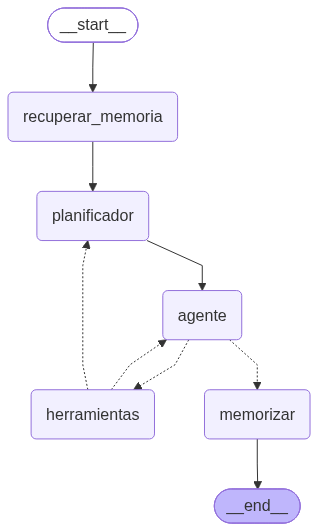

In [ ]:
import sqlite3
from typing import TypedDict, Annotated
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage, ToolMessage, RemoveMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.sqlite import SqliteSaver

class EstadoAgente(TypedDict, total=False):
    messages: Annotated[list, add_messages]
    plan: dict
    contexto_memoria: str
    resumen: str
    replanificaciones: int
    traza: list            # bitácora de decisiones del turno (para demostrar el razonamiento)

def _ultimo_humano(mensajes) -> str:
    for m in reversed(mensajes):
        if isinstance(m, HumanMessage):
            return m.content
    return ""

def _a_texto(mensajes, limite=12) -> str:
    lineas = []
    for m in mensajes[-limite:]:
        if isinstance(m, HumanMessage):
            lineas.append(f"Usuario: {m.content}")
        elif isinstance(m, AIMessage) and limpiar(m.content):
            lineas.append(f"Agente: {limpiar(m.content)[:400]}")
        elif isinstance(m, ToolMessage):
            lineas.append(f"Herramienta: {str(m.content)[:300]}")
    return "\n".join(lineas)

def _toolmessages_finales(mensajes):
    finales = []
    for m in reversed(mensajes):
        if isinstance(m, ToolMessage):
            finales.append(m)
        else:
            break
    return finales

# ---------- Nodo 1: recuperación de contexto (IE4) ----------
def nodo_recuperar_memoria(state: EstadoAgente, config: RunnableConfig):
    uid = _usuario(config)
    pregunta = _ultimo_humano(state["messages"])
    perfil = _leer_json(PERFILES_PATH, {}).get(uid, {})
    try:
        recuerdos = memoria_lp.similarity_search(pregunta, k=3, filter={"user_id": uid})
    except Exception:
        recuerdos = []
    partes = []
    if perfil:
        partes.append("Perfil: " + "; ".join(f"{k}={v}" for k, v in perfil.items()))
    if recuerdos:
        partes.append("Interacciones previas relacionadas:\n" + "\n".join(f"- {d.page_content}" for d in recuerdos))
    contexto = "\n".join(partes) or "(sin memoria previa de este usuario)"
    return {"contexto_memoria": contexto, "replanificaciones": 0,
            "traza": [f"🧠 Memoria: perfil con {len(perfil)} datos, {len(recuerdos)} recuerdos semánticos recuperados"]}

# ---------- Nodo 2: planificación / replanificación (IE5) ----------
def nodo_planificador(state: EstadoAgente):
    alertas = [str(m.content) for m in _toolmessages_finales(state["messages"]) if "[REPLANIFICAR]" in str(m.content)]
    replan = bool(alertas)
    modo = ""
    if replan:
        modo = ("\nREPLANIFICACIÓN: las herramientas detectaron una condición cambiante:\n" + "\n".join(alertas) +
                "\nAjusta el plan: no repitas pasos ya ejecutados, informa la incidencia y prioriza el escalamiento.")
    prompt = PROMPT_PLANIFICADOR.format(
        herramientas=", ".join(t.name for t in TOOLS), modo=modo,
        resumen=state.get("resumen") or "(ninguno)", memoria=state.get("contexto_memoria", ""),
        conversacion=_a_texto(state["messages"]))
    try:
        plan = planificador_llm.invoke([HumanMessage(content=prompt)]).model_dump()
    except Exception as e:   # tolerancia a fallos: plan por defecto
        plan = {"intencion": _ultimo_humano(state["messages"])[:100], "categoria": "otro", "urgencia": "media",
                "pasos": [{"orden": 1, "accion": "Buscar en base de conocimientos", "herramienta": "buscar_base_conocimiento", "prioridad": "alta"},
                          {"orden": 2, "accion": "Responder al usuario", "herramienta": "ninguna", "prioridad": "media"}]}
    traza = state.get("traza", []) + [
        ("🔁 REPLANIFICACIÓN por condición cambiante" if replan else "📋 Plan inicial") + f"\n{plan_a_texto(plan)}"]
    return {"plan": plan, "traza": traza,
            "replanificaciones": state.get("replanificaciones", 0) + (1 if replan else 0)}

# ---------- Nodo 3: agente ejecutor (ReAct) ----------
def _ventana(mensajes, turnos=MAX_TURNOS_CP):
    idx_humanos = [i for i, m in enumerate(mensajes) if isinstance(m, HumanMessage)]
    if len(idx_humanos) <= turnos:
        return mensajes
    return mensajes[idx_humanos[-turnos]:]

def nodo_agente(state: EstadoAgente):
    sistema = PROMPT_AGENTE.format(
        fecha=f"{datetime.now():%Y-%m-%d %H:%M}", resumen=state.get("resumen") or "(ninguno)",
        memoria=state.get("contexto_memoria", ""), plan=plan_a_texto(state.get("plan", {})))
    respuesta = llm_con_tools.invoke([SystemMessage(content=sistema)] + _ventana(state["messages"]))
    if respuesta.tool_calls:
        evento = "🔧 Decide usar: " + ", ".join(f"{tc['name']}({json.dumps(tc['args'], ensure_ascii=False)[:120]})"
                                                for tc in respuesta.tool_calls)
    else:
        evento = "💬 Redacta la respuesta final"
    return {"messages": [respuesta], "traza": state.get("traza", []) + [evento]}

# ---------- Nodo 4: memorización (IE3) ----------
def nodo_memorizar(state: EstadoAgente, config: RunnableConfig):
    uid = _usuario(config)
    pregunta = _ultimo_humano(state["messages"])
    respuesta = limpiar(state["messages"][-1].content)
    plan = state.get("plan", {})
    # a) Memoria de largo plazo episódica
    memoria_lp.add_texts(
        [f"[{datetime.now():%Y-%m-%d}] Consulta ({plan.get('categoria', 'otro')}): {pregunta[:300]} | Respuesta: {respuesta[:400]}"],
        metadatas=[{"user_id": uid, "fecha": f"{datetime.now():%Y-%m-%d %H:%M}", "categoria": plan.get("categoria", "otro")}])
    salida = {"traza": state.get("traza", []) + ["💾 Interacción guardada en memoria de largo plazo"]}
    # b) Compresión de memoria de corto plazo (ventana + resumen)
    mensajes = state["messages"]
    idx_humanos = [i for i, m in enumerate(mensajes) if isinstance(m, HumanMessage)]
    if len(idx_humanos) > MAX_TURNOS_CP:
        corte = idx_humanos[-MAX_TURNOS_CP]
        antiguos = mensajes[:corte]
        prompt = (f"Resume en máximo 6 viñetas los hechos importantes (problemas, tickets, datos del usuario) de esta "
                  f"conversación de soporte. Resumen previo: {state.get('resumen') or '(ninguno)'}\n\n{_a_texto(antiguos, limite=100)}")
        salida["resumen"] = limpiar(llm.invoke([HumanMessage(content=prompt)]).content)
        salida["messages"] = [RemoveMessage(id=m.id) for m in antiguos]
        salida["traza"].append(f"🗜️ Memoria de corto plazo comprimida: {len(antiguos)} mensajes → resumen")
    return salida

# ---------- Enrutadores (toma de decisiones del flujo) ----------
def ruta_agente(state: EstadoAgente):
    return "herramientas" if getattr(state["messages"][-1], "tool_calls", None) else "memorizar"

def ruta_herramientas(state: EstadoAgente):
    alerta = any("[REPLANIFICAR]" in str(m.content) for m in _toolmessages_finales(state["messages"]))
    if alerta and state.get("replanificaciones", 0) < MAX_REPLAN:
        return "planificador"
    return "agente"

# ---------- Construcción del grafo ----------
grafo = StateGraph(EstadoAgente)
grafo.add_node("recuperar_memoria", nodo_recuperar_memoria)
grafo.add_node("planificador", nodo_planificador)
grafo.add_node("agente", nodo_agente)
grafo.add_node("herramientas", ToolNode(TOOLS))
grafo.add_node("memorizar", nodo_memorizar)

grafo.add_edge(START, "recuperar_memoria")
grafo.add_edge("recuperar_memoria", "planificador")
grafo.add_edge("planificador", "agente")
grafo.add_conditional_edges("agente", ruta_agente, {"herramientas": "herramientas", "memorizar": "memorizar"})
grafo.add_conditional_edges("herramientas", ruta_herramientas, {"planificador": "planificador", "agente": "agente"})
grafo.add_edge("memorizar", END)

conexion = sqlite3.connect(CHECKPOINT_DB, check_same_thread=False)
agente_ti = grafo.compile(checkpointer=SqliteSaver(conexion))
print("✅ Agente compilado")

# Diagrama de orquestación generado desde el propio grafo (úsalo en el README / informe)
try:
    from IPython.display import Image, display
    display(Image(agente_ti.get_graph().draw_mermaid_png()))
except Exception:
    print(agente_ti.get_graph().draw_mermaid())

In [ ]:
def conversar(mensaje: str, user_id: str, thread_id: str, verbose: bool = True) -> str:
    '''Envía un mensaje al agente. thread_id = sesión (memoria corto plazo); user_id = persona (memoria largo plazo).'''
    config = {"configurable": {"user_id": user_id, "thread_id": thread_id}, "recursion_limit": 30}
    resultado = agente_ti.invoke({"messages": [HumanMessage(content=mensaje)]}, config)
    respuesta = limpiar(resultado["messages"][-1].content)
    if verbose:
        print(f"👤 [{user_id} · {thread_id}] {mensaje}\n")
        print("—— Traza de decisiones ——")
        for paso in resultado.get("traza", []):
            print(paso)
        print(f"\n🤖 MesaTI:\n{respuesta}\n" + "=" * 90)
    return respuesta

## 8. Pruebas unitarias de herramientas (evidencia de pruebas)

Se prueban las herramientas de forma determinística, **sin llamar al LLM**, para validar la lógica de negocio.

In [ ]:
CFG_TEST = {"configurable": {"user_id": "test_unitario"}}
resultados_pruebas = []

def prueba(nombre, condicion):
    resultados_pruebas.append((nombre, bool(condicion)))
    print(("✅" if condicion else "❌"), nombre)

# Razonamiento: matriz de prioridad
prueba("Incidente masivo que bloquea trabajo → P1", calcular_prioridad("vpn caída", 25, True, True)["prioridad"] == "P1")
prueba("Consulta individual no urgente → P4", calcular_prioridad("duda sobre actualizaciones", 1)["prioridad"] == "P4")
prueba("Palabra de urgencia sube la urgencia", calcular_prioridad("no puedo imprimir", 1)["urgencia"] == 2)

# Consulta: RAG con umbral
prueba("KB encuentra procedimiento de bloqueo", "Fuente 1" in buscar_base_conocimiento.invoke({"consulta": "cuenta bloqueada contraseña"}))
prueba("KB detecta consultas fuera de dominio", "[SIN_RESULTADOS]" in buscar_base_conocimiento.invoke({"consulta": "receta de empanadas de pino"}))

# Consulta: entorno cambiante
simular_cambio_servicio("vpn", "caido")
prueba("Servicio caído emite señal de replanificación", "[REPLANIFICAR]" in consultar_estado_servicio.invoke({"servicio": "VPN"}))
simular_cambio_servicio("vpn", "operativo")
prueba("Servicio operativo no replanifica", "[REPLANIFICAR]" not in consultar_estado_servicio.invoke({"servicio": "vpn"}))

# Escritura: tickets sin duplicados
args = {"titulo": "Prueba", "descripcion": "desc", "categoria": "impresion", "prioridad": "P3"}
r1 = crear_ticket.invoke(args, config=CFG_TEST)
r2 = crear_ticket.invoke(args, config=CFG_TEST)
prueba("Crea ticket nuevo", "creado" in r1)
prueba("No duplica ticket abierto de la misma categoría", "Ya existía" in r2)
prueba("Consulta tickets del usuario", "impresion" in consultar_tickets.invoke({}, config=CFG_TEST))

# Limpieza de datos de prueba
_escribir_json(TICKETS_PATH, [t for t in _leer_json(TICKETS_PATH, []) if t["usuario"] != "test_unitario"])
print(f"\nResultado: {sum(ok for _, ok in resultados_pruebas)}/{len(resultados_pruebas)} pruebas aprobadas")

✅ Incidente masivo que bloquea trabajo → P1
✅ Consulta individual no urgente → P4
✅ Palabra de urgencia sube la urgencia
✅ KB encuentra procedimiento de bloqueo
✅ KB detecta consultas fuera de dominio
🌐 Entorno: el servicio 'vpn' ahora está 'caido'
✅ Servicio caído emite señal de replanificación
🌐 Entorno: el servicio 'vpn' ahora está 'operativo'
✅ Servicio operativo no replanifica
✅ Crea ticket nuevo
✅ No duplica ticket abierto de la misma categoría
✅ Consulta tickets del usuario

Resultado: 10/10 pruebas aprobadas


/tmp/ipykernel_794/737534190.py:12: UserWarning: Relevance scores must be between 0 and 1, got [(Document(id='27461cc3bd7002374b5b2fba99344b7e', metadata={'source': 'data/documento_conocimiento.txt'}, page_content='4. Actualizaciones de software: Las actualizaciones críticas del sistema operativo se despliegan automáticamente todos los viernes a las 22:00 hrs.\n\n5. Correo institucional: Si el correo no sincroniza en el celular, elimine la cuenta del dispositivo y vuelva a agregarla usando autenticación moderna con 2FA.'), -0.028522372245788574), (Document(id='78feb9f6dff7a27247db5a197fd411a8', metadata={'source': 'data/documento_conocimiento.txt'}, page_content='Base de Conocimientos Oficial - Soporte TI Duoc UC\n--------------------------------------------------\n1. Bloqueo de cuentas: Si un usuario olvida su contraseña o la cuenta se bloquea tras 3 intentos fallidos, debe contactar al administrador de red local o utilizar el portal de autoservicio para restablecerla mediante correo 

## 9. Escenarios de demostración: toma de decisiones adaptativa (IE5, IE7)

Cada escenario muestra la **traza de decisiones**: plan, herramientas elegidas, replanificaciones y uso de memoria.

### Escenario 1 — Consulta resoluble con la base de conocimientos

In [ ]:
conversar("¿Qué debo hacer si se bloquea mi cuenta?", user_id="ana.perez", thread_id="demo-1")

👤 [ana.perez · demo-1] ¿Qué debo hacer si se bloquea mi cuenta?

—— Traza de decisiones ——
🧠 Memoria: perfil con 0 datos, 0 recuerdos semánticos recuperados
📋 Plan inicial
Intención: Orientar al usuario sobre los pasos a seguir si su cuenta se bloquea | Categoría: cuentas | Urgencia: media
  1. [alta] Buscar en la base de conocimientos el procedimiento oficial para desbloquear una cuenta → buscar_base_conocimiento
  2. [alta] Consultar el estado del servicio de portal de autoservicio para confirmar que está disponible → consultar_estado_servicio
  3. [media] Clasificar la prioridad del caso según el impacto del bloqueo en el trabajo del usuario → clasificar_prioridad
  4. [media] Crear un ticket de soporte para el desbloqueo de la cuenta si el usuario no puede resolverlo por autoservicio → crear_ticket
  5. [alta] Responder al usuario con los pasos claros: intentar desbloqueo por portal de autoservicio, y si no, indicar el ticket creado y tiempos estimados → ninguna
🔧 Decide usar: busc

'Si tu cuenta se bloquea (por ejemplo, tras 3 intentos fallidos de contraseña), sigue estos pasos:\n\n- **Opción 1 – Portal de autoservicio:** Restablece tu contraseña mediante tu correo institucional. El portal de autoservicio está **operativo** en este momento, así que puedes usarlo de inmediato [Fuente 1].\n- **Opción 2 – Administrador de red local:** Si no logras resolverlo por autoservicio, contacta al administrador de red de tu sede [Fuente 1].\n\nComo respaldo, ya creé un ticket por si necesitas que te desbloqueemos la cuenta:\n\n- **Ticket:** TK-0001 (prioridad P3, SLA de atención: 24 horas, vence 2026-10-30 16:20).\n\n¿Te gustaría que te ayude con algo más?'

### Escenario 2 — Condición cambiante: la VPN se cae a mitad de la conversación
Misma pregunta, distinto entorno → distinto comportamiento. En el segundo turno el agente detecta la caída, **replanifica**, razona la prioridad (25 usuarios, bloquea clase) y crea un ticket.

In [ ]:
simular_cambio_servicio("vpn", "operativo")
conversar("¿Cómo me conecto a la VPN para entrar a los laboratorios?", user_id="luis.soto", thread_id="demo-2")

simular_cambio_servicio("vpn", "caido")
conversar("Lo intenté y no conecta. Somos 25 personas del laboratorio sin acceso y tenemos clase ahora.",
          user_id="luis.soto", thread_id="demo-2")
simular_cambio_servicio("vpn", "operativo")

🌐 Entorno: el servicio 'vpn' ahora está 'operativo'
👤 [luis.soto · demo-2] ¿Cómo me conecto a la VPN para entrar a los laboratorios?

—— Traza de decisiones ——
🧠 Memoria: perfil con 0 datos, 0 recuerdos semánticos recuperados
📋 Plan inicial
Intención: El usuario necesita instrucciones para conectarse a la VPN y acceder a los laboratorios | Categoría: vpn | Urgencia: media
  1. [alta] Verificar el estado actual del servicio VPN para confirmar que está operativo → consultar_estado_servicio
  2. [alta] Buscar en la base de conocimientos las instrucciones oficiales de conexión a la VPN para laboratorios → buscar_base_conocimiento
  3. [media] Consultar el historial del usuario para verificar si ya tiene credenciales o configuraciones previas de VPN → recordar_historial_usuario
  4. [alta] Responder al usuario con las instrucciones de conexión a la VPN, incluyendo credenciales, pasos de configuración y acceso a los laboratorios → ninguna
🔧 Decide usar: consultar_estado_servicio({"servicio":

### Escenario 3 — Problema fuera de la base de conocimientos → escalamiento

In [ ]:
conversar("Mi notebook hace un ruido extraño en el ventilador y se apaga solo.", user_id="ana.perez", thread_id="demo-3")

👤 [ana.perez · demo-3] Mi notebook hace un ruido extraño en el ventilador y se apaga solo.

—— Traza de decisiones ——
🧠 Memoria: perfil con 0 datos, 1 recuerdos semánticos recuperados
📋 Plan inicial
Intención: Diagnosticar y resolver el ruido extraño del ventilador y los apagados espontáneos de la notebook del usuario | Categoría: otro | Urgencia: media
  1. [alta] Buscar en la base de conocimientos soluciones para ruido de ventilador y apagados espontáneos en notebooks → buscar_base_conocimiento
  2. [media] Consultar el historial del usuario para verificar si ha reportado problemas similares de hardware antes → recordar_historial_usuario
  3. [media] Clasificar la prioridad del caso según el impacto en el trabajo del usuario → clasificar_prioridad
  4. [alta] Crear un ticket de soporte para el problema de hardware (ventilador y apagados) → crear_ticket
  5. [baja] Guardar los datos relevantes del equipo y el síntoma reportado en el perfil del usuario → guardar_dato_usuario
  6. [alta

'Listo, ya registré tu caso. Te resumo:\n\n**Ticket creado: TK-0003** (prioridad P3, SLA de 24 h – vence 2026-10-30 16:24)\n\nLamentablemente no poseo esa información en mi base de conocimientos actual, por eso lo escalé directamente a Nivel 2 para revisión técnica. Mientras tanto, te recomiendo estas medidas de cuidado:\n\n- **No la uses sobre superficies blandas** (cama, cojín, manta); apóyala sobre una superficie plana y rígida para que el ventilador tenga flujo de aire.\n- **Evita usarla en espacios cerrados o calurosos**; si es posible, en un lugar ventilado.\n- **Guarda tu trabajo con frecuencia** (Ctrl+S) y, si es posible, copia tus archivos a la nube o a un pendrive, por si se apaga de nuevo.\n- **No la fuerces a encenderse** si se apaga sola; déjala enfriar unos minutos antes de volver a intentarlo.\n- **No la abras ni intentes limpiar el ventilador tú mismo/a**, para no dañar componentes ni perder la garantía.\n\nEl equipo de Nivel 2 se pondrá en contacto contigo dentro de la

### Escenario 4 — Varios problemas: planificación con prioridades

In [ ]:
conversar("Tengo dos cosas: la impresora del laboratorio aparece 'En pausa', y además mi cuenta quedó bloqueada "
          "y tengo que rendir una prueba en una hora.", user_id="ana.perez", thread_id="demo-4")

👤 [ana.perez · demo-4] Tengo dos cosas: la impresora del laboratorio aparece 'En pausa', y además mi cuenta quedó bloqueada y tengo que rendir una prueba en una hora.

—— Traza de decisiones ——
🧠 Memoria: perfil con 1 datos, 2 recuerdos semánticos recuperados
📋 Plan inicial
Intención: Resolver dos problemas: impresora del laboratorio en pausa y cuenta de usuario bloqueada, con urgencia alta por prueba en 1 hora | Categoría: impresion | Urgencia: alta
  1. [alta] Verificar el estado actual del servicio de impresión para confirmar si la pausa es local o por caída del servicio → consultar_estado_servicio
  2. [alta] Buscar en la base de conocimientos los pasos para despausar la impresora del laboratorio y para desbloquear una cuenta → buscar_base_conocimiento
  3. [alta] Clasificar la prioridad del caso considerando la prueba en 1 hora (bloquea trabajo del usuario) → clasificar_prioridad
  4. [alta] Crear un ticket para el bloqueo de cuenta con prioridad alta y otro para la impresora en p

'Entiendo la urgencia. Te resumo ambos casos:\n\n**1. Cuenta bloqueada (prioridad P1 – SLA 4 h)**\n- Ya existía el ticket **TK-0001** para cuentas; se agregó tu nuevo reporte como nota.\n- Mientras tanto, puedes desbloquearte tú mismo:\n  - **Portal de autoservicio** (operativo ahora): restablece tu contraseña con tu correo institucional [Fuente 1].\n  - Si no logras acceso, contacta al **administrador de red local** [Fuente 1].\n\n**2. Impresora del laboratorio "En pausa" (prioridad P4 – SLA 72 h)**\n- El servicio de impresión global está **operativo**, así que la pausa es local.\n- **Ticket TK-0004** creado.\n- Solución inmediata: en Windows abre `services.msc` → **Cola de impresión** → clic derecho → **Reiniciar** [Fuente 1].\n\n¿Necesitas ayuda con el restablecimiento de contraseña o con reiniciar la cola de impresión?'

### Escenario 5 — Memoria de corto plazo (misma sesión)
El agente guarda un dato estable y luego responde a referencias implícitas del mismo hilo.

In [ ]:
conversar("Para que lo tengas presente: trabajo en el edificio B, laboratorio 3.", user_id="ana.perez", thread_id="demo-5")
conversar("¿Qué tickets tengo abiertos?", user_id="ana.perez", thread_id="demo-5")

estado = agente_ti.get_state({"configurable": {"thread_id": "demo-5"}})
print(f"📦 Mensajes guardados en el checkpoint del hilo demo-5: {len(estado.values['messages'])}")

👤 [ana.perez · demo-5] Para que lo tengas presente: trabajo en el edificio B, laboratorio 3.

—— Traza de decisiones ——
🧠 Memoria: perfil con 2 datos, 3 recuerdos semánticos recuperados
📋 Plan inicial
Intención: Registrar en el perfil del usuario su ubicación de trabajo (Edificio B, Laboratorio 3) para futuras consultas de soporte. | Categoría: otro | Urgencia: baja
  1. [alta] Guardar en la memoria de largo plazo del usuario su ubicación de trabajo: Edificio B, Laboratorio 3. → guardar_dato_usuario
  2. [media] Confirmar al usuario que su ubicación (Edificio B, Laboratorio 3) quedó registrada para futuros casos de soporte. → ninguna
🔧 Decide usar: guardar_dato_usuario({"clave": "ubicacion", "valor": "Edificio B, Laboratorio 3"})
💬 Redacta la respuesta final
💾 Interacción guardada en memoria de largo plazo

🤖 MesaTI:
¡Listo! ✅

- **Ubicación registrada:** Edificio B, Laboratorio 3.
- La tendré presente en futuras consultas de soporte para agilizar la atención.

¿Hay algo más en lo que 

### Escenario 6 — Memoria de largo plazo (nueva sesión, mismo usuario)
Nuevo `thread_id` = sin historial de corto plazo. El agente recupera el perfil y recuerdos semánticos de sesiones anteriores.

In [ ]:
conversar("Hola de nuevo. ¿Recuerdas dónde trabajo y qué problemas reporté antes?", user_id="ana.perez", thread_id="demo-6-nueva")

👤 [ana.perez · demo-6-nueva] Hola de nuevo. ¿Recuerdas dónde trabajo y qué problemas reporté antes?

—— Traza de decisiones ——
🧠 Memoria: perfil con 3 datos, 3 recuerdos semánticos recuperados
📋 Plan inicial
Intención: Recordar al usuario su ubicación y los problemas que reportó previamente | Categoría: otro | Urgencia: baja
  1. [alta] Recuperar el historial de interacciones y datos del usuario (ubicación, tickets previos, problemas reportados) → recordar_historial_usuario
  2. [media] Consultar el estado actual del ticket TK-0001 (cuenta bloqueada) para informar si sigue abierto o resuelto → consultar_tickets
  3. [alta] Responder al usuario confirmando su ubicación (Edificio B, Laboratorio 3) y los problemas reportados: cuenta bloqueada (TK-0001 P1), impresora en pausa, y ruido en ventilador/apagados espontáneos del notebook → ninguna
🔧 Decide usar: recordar_historial_usuario({"consulta": "ubicación, problemas reportados, tickets previos"}), consultar_tickets({"ticket_id": "TK-0001"

'¡Hola de nuevo! 👋 Sí, tengo todo registrado. Te resumo:\n\n**📍 Tu ubicación:**\n- Edificio B, Laboratorio 3\n\n**📋 Problemas que reportaste hoy (2026-10-29):**\n\n| Ticket | Problema | Estado | Prioridad |\n|--------|----------|--------|-----------|\n| **TK-0001** | Cuenta bloqueada – solicitud de desbloqueo | Abierto | P3 (SLA vence 2026-10-30 16:20) |\n| **TK-0003** | Ruido en ventilador y apagados espontáneos en tu notebook | Abierto | P3 |\n| **TK-0004** | Impresora del laboratorio en "En pausa" | Abierto | P4 |\n\nAdemás, me indicaste que tenías una **prueba pendiente en 1 hora**, por lo que la cuenta bloqueada era la más urgente en ese momento.\n\n¿Quieres que revise el estado actual de alguno de estos tickets o necesitas ayuda con algo más?'

### Escenario 7 — Flujo prolongado: compresión de memoria
Se envían más turnos que `MAX_TURNOS_CP`; los antiguos se resumen y el agente mantiene la coherencia.

In [ ]:
hilo = "demo-7-largo"
mensajes_largos = ["Hola, soy Pedro del área de finanzas.", "¿Cuándo se instalan las actualizaciones críticas?",
                   "¿Y cómo conecto el correo en mi celular?", "¿La red Wi-Fi usa las mismas credenciales?",
                   "¿Qué hago si la impresora está en pausa?", "¿Qué SLA tiene un incidente P2?",
                   "Gracias. ¿Necesito 2FA para la VPN?"]
for m in mensajes_largos:
    conversar(m, user_id="pedro.rojas", thread_id=hilo, verbose=False)

conversar("Resumiendo, ¿de qué área te dije que era y qué temas vimos?", user_id="pedro.rojas", thread_id=hilo)
estado = agente_ti.get_state({"configurable": {"thread_id": hilo}})
print(f"📦 Mensajes en ventana: {len(estado.values['messages'])}\n🗜️ Resumen acumulado:\n{estado.values.get('resumen')}")

/tmp/ipykernel_794/737534190.py:12: UserWarning: Relevance scores must be between 0 and 1, got [(Document(id='b0658b7c6aa6248ae74dd2de8618cfef', metadata={'source': 'data/documento_conocimiento.txt'}, page_content="2. Configuración de VPN: Para acceder remotamente a los laboratorios, es obligatorio utilizar la VPN corporativa con autenticación de doble factor (2FA).\n\n3. Impresoras de red: Si una impresora muestra el estado 'En pausa', reinicie el servicio de cola de impresión en Windows (services.msc -> Cola de impresión -> Reiniciar)."), 0.3025357723236084), (Document(id='27461cc3bd7002374b5b2fba99344b7e', metadata={'source': 'data/documento_conocimiento.txt'}, page_content='4. Actualizaciones de software: Las actualizaciones críticas del sistema operativo se despliegan automáticamente todos los viernes a las 22:00 hrs.\n\n5. Correo institucional: Si el correo no sincroniza en el celular, elimine la cuenta del dispositivo y vuelva a agregarla usando autenticación moderna con 2FA.'),

👤 [pedro.rojas · demo-7-largo] Resumiendo, ¿de qué área te dije que era y qué temas vimos?

—— Traza de decisiones ——
🧠 Memoria: perfil con 0 datos, 3 recuerdos semánticos recuperados
📋 Plan inicial
Intención: Pedro pide un resumen de su área y los temas tratados en la conversación | Categoría: otro | Urgencia: baja
  1. [alta] Recuperar el historial de interacciones del usuario para confirmar área y temas tratados → recordar_historial_usuario
  2. [alta] Responder al usuario con el resumen: área de finanzas y temas vistos (actualizaciones críticas, Wi-Fi, impresión, SLA P2, VPN con 2FA) → ninguna
🔧 Decide usar: recordar_historial_usuario({"consulta": "área del usuario y temas tratados en la conversación"})
💬 Redacta la respuesta final
💾 Interacción guardada en memoria de largo plazo
🗜️ Memoria de corto plazo comprimida: 5 mensajes → resumen

🤖 MesaTI:
¡Hola, Pedro! 👋

Aquí va el resumen de nuestra conversación:

**Tu área:**
- **Finanzas** 📊

**Temas que revisamos:**
- **Correo en el 

In [ ]:
print("🎫 Tickets registrados por el agente:")
print(json.dumps(_leer_json(TICKETS_PATH, []), ensure_ascii=False, indent=2))

🎫 Tickets registrados por el agente:
[
  {
    "id": "TK-0001",
    "usuario": "ana.perez",
    "titulo": "Cuenta bloqueada - solicitud de desbloqueo",
    "descripcion": "El usuario consulta el procedimiento a seguir si su cuenta se bloquea. Se le orientó a usar el portal de autoservicio (operativo) o contactar al administrador de red local. Ticket de respaldo por si no logra desbloquearla por autoservicio.",
    "categoria": "cuentas",
    "prioridad": "P3",
    "estado": "abierto",
    "creado": "2026-10-29 16:20",
    "vence": "2026-10-30 16:20",
    "notas": [
      "2026-10-29 16:26 Nuevo reporte vinculado: Cuenta de usuario bloqueada. El usuario debe rendir una prueba en 1 hora, por lo que necesita acceso inmediato. El portal de autoservicio está operativo para restablecer la contraseña."
    ]
  },
  {
    "id": "TK-0002",
    "usuario": "luis.soto",
    "titulo": "Caída del servicio VPN - 25 usuarios de laboratorio sin acceso (clase en curso)",
    "descripcion": "El servicio 

## 10. Interfaz para la demo en vivo (Gradio)
Incluye un **panel de control del entorno** para cambiar el estado de los servicios durante la presentación y ver cómo el agente adapta su comportamiento.

In [ ]:
import gradio as gr

def responder_chatbot(mensaje, historial, user_id, thread_id):
    try:
        config = {"configurable": {"user_id": user_id or "anonimo", "thread_id": thread_id or "gradio"},
                  "recursion_limit": 30}
        resultado = agente_ti.invoke({"messages": [HumanMessage(content=mensaje)]}, config)
        respuesta = limpiar(resultado["messages"][-1].content)
        traza = "\n\n".join(resultado.get("traza", []))
        return f"{respuesta}\n\n<details><summary>🧭 Ver razonamiento del agente</summary>\n\n```\n{traza}\n```\n</details>"
    except Exception as e:
        return f"Ocurrió un error al procesar la consulta: {e}"

def cambiar_servicio(servicio, estado):
    simular_cambio_servicio(servicio, estado)
    return _leer_json(ESTADO_SERVICIOS_PATH, {})

with gr.Blocks(title="MesaTI - Agente de Soporte TI") as demo:
    gr.Markdown("# 🤖 MesaTI — Agente de Soporte TI\nAgente con herramientas, memoria y planificación adaptativa.")
    with gr.Row():
        with gr.Column(scale=3):
            user_box = gr.Textbox(value="ana.perez", label="ID de usuario (memoria de largo plazo)")
            thread_box = gr.Textbox(value="sesion-demo", label="ID de sesión (memoria de corto plazo)")
            gr.ChatInterface(fn=responder_chatbot, additional_inputs=[user_box, thread_box],
                             textbox=gr.Textbox(placeholder="Ej: No me conecta la VPN y tengo clase...", scale=7))
        with gr.Column(scale=1):
            gr.Markdown("### 🌐 Entorno simulado")
            servicio = gr.Dropdown(list(ESTADO_INICIAL), value="vpn", label="Servicio")
            estado_dd = gr.Dropdown(["operativo", "degradado", "caido"], value="caido", label="Nuevo estado")
            estado_json = gr.JSON(value=_leer_json(ESTADO_SERVICIOS_PATH, {}), label="Estado actual")
            gr.Button("Aplicar cambio").click(cambiar_servicio, [servicio, estado_dd], estado_json)
            tickets_json = gr.JSON(label="Tickets")
            gr.Button("Ver tickets").click(lambda: _leer_json(TICKETS_PATH, []), None, tickets_json)

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://007cac44a8d998afee.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
